# 04 · Light collection of the triangular bars and energy dependence of the smearing

The bar-size scan (notebook 03) used the same light yield per MeV for every bar. Here a Geant4 optical simulation of one bar (`optical/sithopt`) gives the **light-collection efficiency** ε of each geometry, i.e. photons reaching the SiPMs over photons emitted. ε is then used in two ways:

1. **Relative scale (normalised on the test beam):** if all the test-beam smearing were photostatistics, a bar with efficiency ε would have the PHOTOSTAT smearing s = s_proto · √(ε_proto / ε), with s_proto = 0.180 at E_ref = 7 MeV (notebook 02). This is the **OPTICAL** model of the scan.
2. **Absolute scale:** ε × light yield × PDE gives the photoelectrons per MeV, which can be compared with the number implied by the test-beam smearing (≈ 25 p.e./MeV if it were all photostatistics).

**Read-out as built for the 2018 prototype** (thesis ch. 4, F. Müller, Hyperfine Interact. 240 (2019) 10): one triangular pre-amplifier board (QS Electronics) per bar end, two channels of two KETEK PM6660TP-SB0 SiPMs (6 × 6 mm²), placed along the two slanted sides of the triangle. A white 3D-printed mask fills the rest of the board, and a thin silicone pad gives the optical contact between the SiPMs and the bar. The bars are wrapped in Teflon and then black Tedlar. **Here: 4 SiPMs of 6 × 6 mm² for every geometry**, on one end, as on the board. Where the end face is too small, the SiPMs are clipped to the face.

**Model and assumptions** (`optical/run_optical.sh`, results in `~/runs/optical`):

| item | value | source |
|---|---|---|
| bar | isosceles triangle b × h, 420 mm long (fixed active area) | scan geometry |
| EJ-200 | n = 1.58, bulk attenuation 380 cm, emission peak 425 nm | Eljen data sheet (thesis tab. 4.1) |
| bar surface | polished (micro-facet slope σ_α = 0.01 rad) | assumption |
| wrapping | Teflon, Lambertian, R = 0.95, with an air gap; nothing comes back from outside (black Tedlar) | assumption on R |
| far end | Teflon | assumption |
| read-out end | 1 mm silicone pad (n = 1.43) on the whole face; behind it the SiPMs (window n = 1.55) and the white mask (Lambertian, R = 0.80) | thesis; n and R assumed |
| emission | uniform in the bar volume (= tracks uniformly crossing the bar), isotropic | |
| SiPM | a photon entering a SiPM is counted; the PDE is applied afterwards | |

Systematics on five geometries: R_wrap 0.90 / 0.98, R_mask 0.50 / 0.95, attenuation 200 cm, rough surface (σ_α = 0.1 rad), air instead of the silicone pad, and the layout 2 + 2 (one SiPM per slanted side at each end). The optical constants do not depend on the wavelength, so the spectrum only matters for the PDE.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import sithplot as sp
sp.setup()
import optical_summary as osum
O = sp.RUNS / "optical"
opt = pd.DataFrame(osum.summary(O))
nom = opt[opt.variant == "nominal"].copy()
BASES, HEIGHTS = sorted(nom.base_mm.unique()), sorted(nom.height_mm.unique())
proto = nom.query("base_mm == 60 and height_mm == 20").iloc[0]
KEY = [(60, 20), (42, 30), (30, 30), (20, 20), (20, 10)]      # fixed series order
key_label = lambda b, h: f"{b} × {h}" + (" (prototype)" if (b, h) == (60, 20) else "")
print(f"{len(opt)} optical runs, {len(nom)} nominal; {proto.n_gen:.2e} photons per nominal run")
print(f"prototype: eps = {proto.eps:.4f} ± {proto.eps_err:.4f}, SiPM area {proto.sensor_area_mm2:.1f} mm²")

65 optical runs, 25 nominal; 5.00e+06 photons per nominal run
prototype: eps = 0.1264 ± 0.0002, SiPM area 144.3 mm²


## 1. The read-out face of each geometry

End faces to scale, with the four 6 × 6 mm² SiPMs (blue) along the slanted sides; the label is the fraction of the face covered by SiPMs. Below h ≈ 10 mm the SiPMs no longer fit and are clipped: for h = 5 mm they cover most of the face.

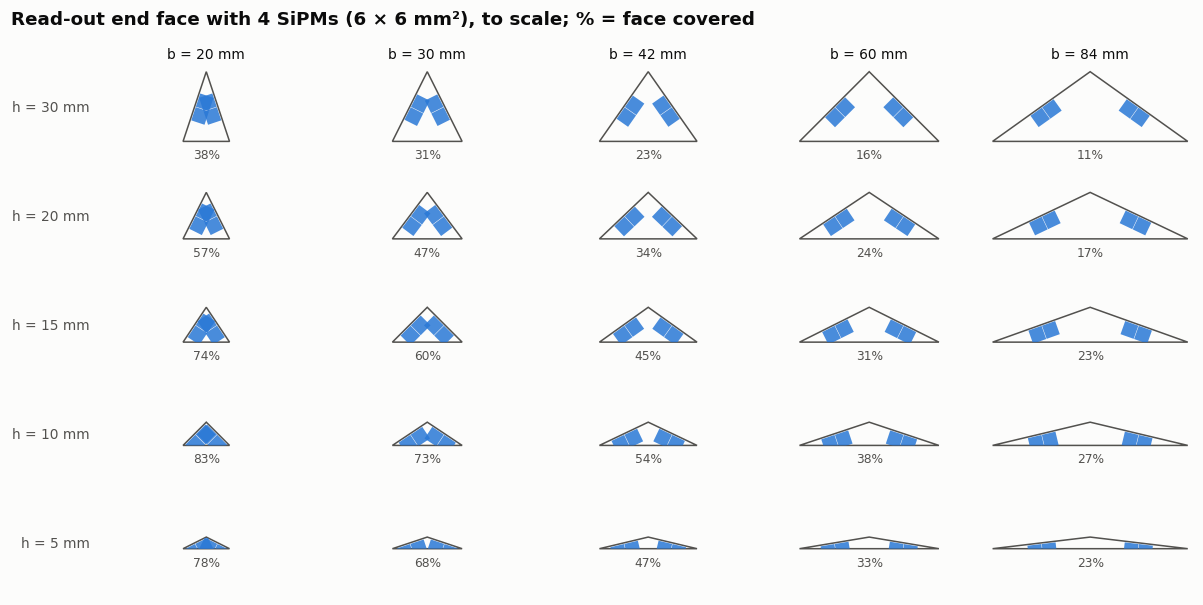

In [2]:
def sipm_squares(b, h, a=6.0, gap=0.2, inset=0.5):
    A, C, B = np.array([-b / 2, -h / 2]), np.array([0, h / 2]), np.array([b / 2, -h / 2])
    out = []
    for side, P in ((-1, A), (1, B)):
        t = (C - P) / np.linalg.norm(C - P)
        n = np.array([t[1], -t[0]]) if side < 0 else np.array([-t[1], t[0]])
        R = np.array([[t[0], -t[1]], [t[1], t[0]]])
        for off in (-(a + gap) / 2, (a + gap) / 2):
            c = (P + C) / 2 + off * t + (inset + a / 2) * n
            out.append(c + (R @ (np.array([[-1, -1], [1, -1], [1, 1], [-1, 1]]) * a / 2).T).T)
    return [A, C, B], out

fig, axs = plt.subplots(len(HEIGHTS), len(BASES), figsize=(11, 5.6))
for i, h in enumerate(sorted(HEIGHTS, reverse=True)):
    for j, b in enumerate(BASES):
        ax = axs[i, j]
        tri, squares = sipm_squares(b, h)
        face = Polygon(tri, closed=True, fc=sp.SURFACE, ec=sp.INK2, lw=1)
        ax.add_patch(face)
        for sq in squares:
            p = Polygon(sq, closed=True, fc=sp.SERIES[0], ec="none", alpha=0.85)
            ax.add_patch(p); p.set_clip_path(face)
        r = nom.query("base_mm == @b and height_mm == @h").iloc[0]
        ax.text(0, -h / 2 - 3, f"{100 * r.sensor_area_mm2 / r.face_area_mm2:.0f}%", ha="center", va="top",
                fontsize=8, color=sp.INK2)
        ax.set(xlim=(-44, 44), ylim=(-22, 17), aspect="equal"); ax.axis("off")
        if i == 0: ax.set_title(f"b = {b} mm", fontsize=9, loc="center", fontweight="normal")
        if j == 0: ax.text(-50, 0, f"h = {h} mm", ha="right", va="center", fontsize=9, color=sp.INK2)
fig.suptitle("Read-out end face with 4 SiPMs (6 × 6 mm²), to scale; % = face covered", x=0.01, ha="left",
             fontweight="bold")
plt.tight_layout(); plt.show()

## 2. Collection efficiency

ε for every geometry and its ratio to the prototype. The OPTICAL smearing follows from the ratio.

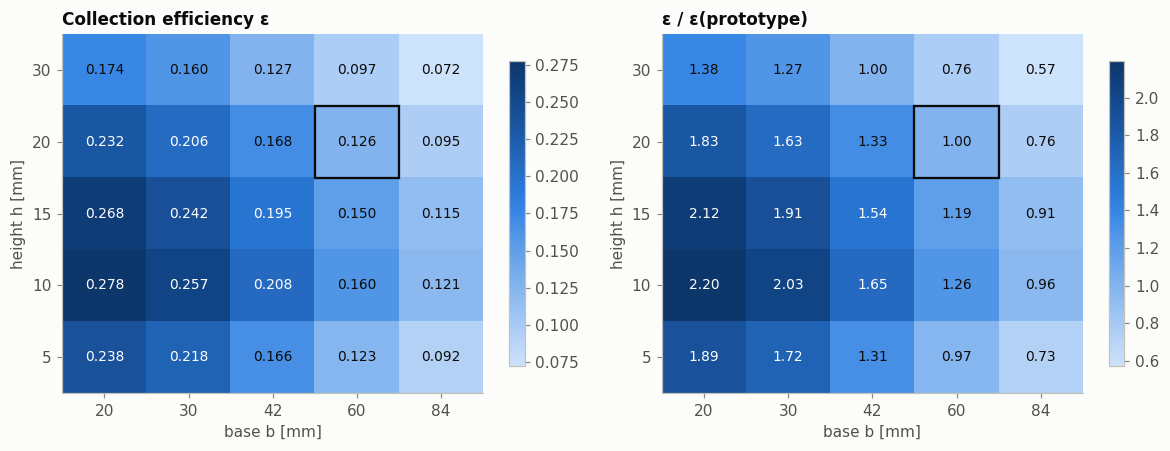

,b [mm],h [mm],SiPM area [mm²],face coverage,ε,ε / ε_proto,OPTICAL s,ε near / far end,transverse rms
0,20,5,39.241,0.785,0.238,1.886,0.131,1.347,0.007
1,20,10,82.759,0.828,0.278,2.196,0.121,1.391,0.004
2,20,15,110.628,0.738,0.268,2.120,0.124,1.460,0.007
3,20,20,113.634,0.568,0.232,1.835,0.133,1.476,0.007
4,20,30,113.070,0.377,0.174,1.378,0.153,1.536,0.011
5,30,5,51.182,0.682,0.218,1.724,0.137,1.374,0.009
6,30,10,109.872,0.732,0.257,2.033,0.126,1.462,0.006
7,30,15,135.799,0.604,0.242,1.914,0.130,1.474,0.007
8,30,20,139.936,0.466,0.206,1.631,0.141,1.549,0.010
9,30,30,141.182,0.314,0.160,1.266,0.160,1.535,0.012


In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, col, title, fmt in ((axs[0], "eps", "Collection efficiency ε", "{:.3f}"),
                            (axs[1], "eps_rel", "ε / ε(prototype)", "{:.2f}")):
    M = nom.pivot(index="height_mm", columns="base_mm", values=col).loc[HEIGHTS, BASES]
    im = ax.imshow(M.values, origin="lower", cmap="sith_blue", aspect="auto")
    for (yi, xi), v in np.ndenumerate(M.values):
        dark = (v - np.nanmin(M.values)) / (np.nanmax(M.values) - np.nanmin(M.values)) > 0.55
        ax.text(xi, yi, fmt.format(v), ha="center", va="center", fontsize=9, color="white" if dark else sp.INK)
    ax.set(xticks=range(len(BASES)), xticklabels=BASES, yticks=range(len(HEIGHTS)), yticklabels=HEIGHTS,
           xlabel="base b [mm]", ylabel="height h [mm]", title=title)
    ax.grid(False)
    i, j = HEIGHTS.index(20), BASES.index(60)
    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=sp.INK, lw=1.5))
    fig.colorbar(im, ax=ax, shrink=0.85)
plt.tight_layout(); plt.show()

tab = nom.sort_values(["base_mm", "height_mm"])[["base_mm", "height_mm", "sensor_area_mm2", "face_area_mm2", "eps",
                                                 "eps_rel", "smear_photostat", "eps_near_far", "u_rms"]].copy()
tab["coverage"] = tab.sensor_area_mm2 / tab.face_area_mm2
tab = tab[["base_mm", "height_mm", "sensor_area_mm2", "coverage", "eps", "eps_rel", "smear_photostat", "eps_near_far", "u_rms"]]
tab.columns = ["b [mm]", "h [mm]", "SiPM area [mm²]", "face coverage", "ε", "ε / ε_proto", "OPTICAL s",
               "ε near / far end", "transverse rms"]
tab.round(3).reset_index(drop=True)

Two effects compete: a smaller face is better covered by the four SiPMs (more light), but a smaller cross-section also means more reflections per unit length, and each one loses a few % on the Teflon. A taller bar at fixed base has a larger face (lower coverage).

## 3. Uniformity along the bar and across the triangle

Along the bar the efficiency falls with the distance from the read-out end (the far end is Teflon). Across the triangle, the response of a track at u = 2x/b (mean ε along the chord) is flat within a few per mil, so the light collection does not bias η.

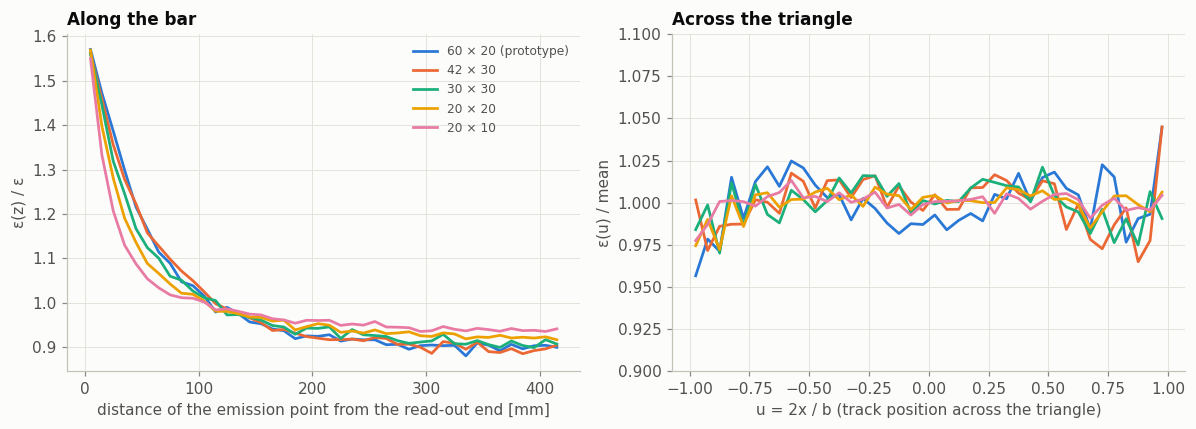

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for i, (b, h) in enumerate(KEY):
    run = osum.load_run(O / f"b{b}_h{h}.root"); m = osum.metrics(run)
    axs[0].plot(m["z"], m["eps_z"] / m["eps"], color=sp.SERIES[i], lw=1.8, label=key_label(b, h))
    axs[1].plot(m["u"], m["eps_u"] / np.nanmean(m["eps_u"]), color=sp.SERIES[i], lw=1.8, label=key_label(b, h))
axs[0].set(xlabel="distance of the emission point from the read-out end [mm]", ylabel="ε(z) / ε",
           title="Along the bar")
axs[1].set(xlabel="u = 2x / b (track position across the triangle)", ylabel="ε(u) / mean",
           title="Across the triangle", ylim=(0.9, 1.1))
axs[0].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

## 4. Optical systematics

ε / ε_proto with the same optical variant for both, i.e. the uncertainty on the *relative* scale that enters the OPTICAL model. Absolute ε in the second table.

In [5]:
sys_ = opt[[(b, h) in KEY for b, h in zip(opt.base_mm, opt.height_mm)]].copy()
sys_["geometry"] = [f"{b} × {h}" for b, h in zip(sys_.base_mm, sys_.height_mm)]
order = ["nominal", "rwrap0.90", "rwrap0.98", "rmask0.50", "rmask0.95", "att200", "sigma0.10", "npad1.00", "both"]
names = {"nominal": "nominal", "rwrap0.90": "R_wrap 0.90", "rwrap0.98": "R_wrap 0.98", "rmask0.50": "R_mask 0.50",
         "rmask0.95": "R_mask 0.95", "att200": "attenuation 200 cm", "sigma0.10": "rough surface (σ_α 0.1)",
         "npad1.00": "air instead of silicone pad", "both": "2 + 2 SiPMs (both ends)"}
cols = [f"{b} × {h}" for b, h in KEY]
rel = sys_.pivot(index="variant", columns="geometry", values="eps_rel").loc[order, cols].rename(index=names)
eps = sys_.pivot(index="variant", columns="geometry", values="eps").loc[order, cols].rename(index=names)
spread = (rel.max() - rel.min()) / rel.loc["nominal"] / 2
print("half spread of eps/eps_proto over the variants:", ", ".join(f"{c}: {100 * v:.1f}%" for c, v in spread.items()))
display(rel.round(3)); display(eps.round(4))

half spread of eps/eps_proto over the variants: 60 × 20: 0.0%, 42 × 30: 1.5%, 30 × 30: 2.0%, 20 × 20: 7.8%, 20 × 10: 19.3%


geometry,60 × 20,42 × 30,30 × 30,20 × 20,20 × 10
variant,,,,,
nominal,1.0,1.002,1.266,1.835,2.196
R_wrap 0.90,1.0,0.999,1.279,1.889,2.306
R_wrap 0.98,1.0,0.998,1.249,1.769,2.073
R_mask 0.50,1.0,0.991,1.294,2.016,2.536
R_mask 0.95,1.0,1.006,1.247,1.728,2.013
attenuation 200 cm,1.0,0.991,1.278,1.936,2.381
rough surface (σ_α 0.1),1.0,1.016,1.259,1.777,2.089
air instead of silicone pad,1.0,0.985,1.253,1.849,2.183
2 + 2 SiPMs (both ends),1.0,1.008,1.298,1.947,2.859


geometry,60 × 20,42 × 30,30 × 30,20 × 20,20 × 10
variant,,,,,
nominal,0.1264,0.1266,0.1601,0.2319,0.2775
R_wrap 0.90,0.1130,0.1129,0.1445,0.2135,0.2606
R_wrap 0.98,0.1476,0.1474,0.1844,0.2612,0.3060
R_mask 0.50,0.1065,0.1056,0.1378,0.2148,0.2701
R_mask 0.95,0.1397,0.1405,0.1742,0.2414,0.2811
attenuation 200 cm,0.1031,0.1022,0.1317,0.1995,0.2453
rough surface (σ_α 0.1),0.1258,0.1278,0.1584,0.2237,0.2629
air instead of silicone pad,0.0716,0.0705,0.0898,0.1325,0.1563
2 + 2 SiPMs (both ends),0.0963,0.0971,0.1251,0.1876,0.2755


## 5. Absolute scale: is the test-beam smearing photostatistics?

Photoelectrons per MeV = light yield × Birks factor × PDE × ε, with 10 000 photons/MeV (EJ-200), Birks factor 0.93 (≈ 5.5 MeV/cm, kB = 0.126 mm/MeV) and an effective PDE of 0.35 for the KETEK SiPMs over the EJ-200 spectrum (assumed; ±30%). The test-beam smearing, if it were all photostatistics, corresponds to σ_E/E = 0.180/2.355 = 7.6% at 7 MeV, i.e. N_pe = 1/0.076² ≈ 171 at 7 MeV ≈ 24 p.e./MeV (more with the SiPM excess noise factor).

In [6]:
npe_tb = 1 / (0.1799 / 2.355) ** 2 / 7.0
p = proto.eps
rows = []
for label, pde, ly, e in (("nominal", 0.35, 1e4, p),
                          ("PDE 0.25", 0.25, 1e4, p),
                          ("light yield −30%", 0.35, 0.7e4, p),
                          ("lowest ε among the variants", 0.35, 1e4, eps["60 × 20"].min()),
                          ("all pessimistic", 0.25, 0.7e4, eps["60 × 20"].min())):
    npe = ly * osum.BIRKS * pde * e
    rows.append(dict(case=label, eps=e, pe_per_MeV=npe, sigma_over_E_at_7MeV=1 / np.sqrt(7 * npe),
                     photostat_fraction_of_TB_variance=(1 / np.sqrt(7 * npe) / (0.1799 / 2.355)) ** 2))
ab = pd.DataFrame(rows)
print(f"test beam, if all photostatistics: {npe_tb:.0f} p.e./MeV, sigma_E/E = {0.1799 / 2.355:.3f} at 7 MeV")
ab.round(3)

test beam, if all photostatistics: 24 p.e./MeV, sigma_E/E = 0.076 at 7 MeV


,case,eps,pe_per_MeV,sigma_over_E_at_7MeV,photostat_fraction_of_TB_variance
0,nominal,0.126,411.439,0.019,0.059
1,PDE 0.25,0.126,293.885,0.022,0.083
2,light yield −30%,0.126,288.007,0.022,0.085
3,lowest ε among the variants,0.072,233.111,0.025,0.105
4,all pessimistic,0.072,116.556,0.035,0.210


## 6. Resolution with the four smearing models

The scan was repeated with two more models, both calibrated on the test beam like PHOTOSTAT (same offset width as CONSTANT 0.22):

| model | σ_E | meaning |
|---|---|---|
| CONSTANT | 0.22/2.355 · E | relative spread, e.g. gain and calibration |
| PHOTOSTAT | s · √(E · 7 MeV)/2.355, s = 0.180 | photostatistics, same light yield for every bar |
| NOISE | s · 7 MeV/2.355, independent of E | electronic noise |
| OPTICAL | PHOTOSTAT with s = 0.180 · √(ε_proto/ε) | photostatistics with the simulated light collection |

For a given geometry the models differ only in how the smearing scales with the deposited energy, which is smaller for lower bars.

In [7]:
import json
S = sp.RUNS / "scan_bars"
cal = json.load(open(S / "calib" / "calibration.json"))
print(f"calibration on the test beam: PHOTOSTAT s = {cal['photostat_smear']:.4f}, NOISE s = {cal['noise_smear']:.4f} "
      f"(σ_E = {cal['noise_smear'] * 7 / 2.355:.3f} MeV)")
df = pd.read_csv(S / "summary.csv"); df["model"] = df.model.str.upper()
MODELS = ["CONSTANT", "PHOTOSTAT", "NOISE", "OPTICAL"]                 # fixed series order
df = df[df.model.isin(MODELS)]
METRICS = [("sigma_r_mm", "σ_r [mm]", "radial position"), ("sigma_rphi_mm", "σ_rφ [mm]", "azimuthal position"),
           ("sigma_theta_deg", "σ_θ [°]", "polar angle"), ("sigma_phi_A_deg", "A [°]  (σ_φ = A·cot θ)", "azimuthal angle")]
print(df.groupby("model").size().to_string())

calibration on the test beam: PHOTOSTAT s = 0.1799, NOISE s = 0.1214 (σ_E = 0.361 MeV)
model
CONSTANT     25
NOISE        25
OPTICAL      25
PHOTOSTAT    25


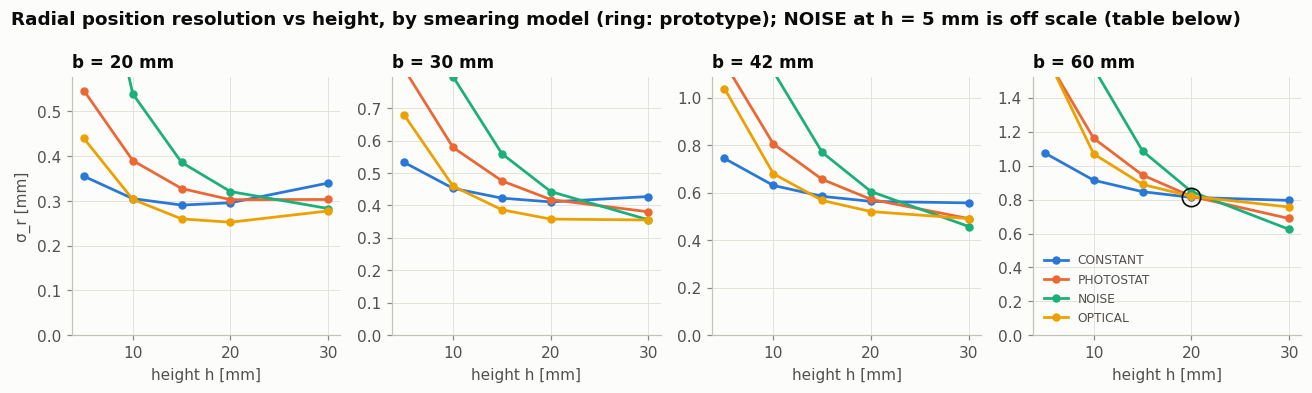

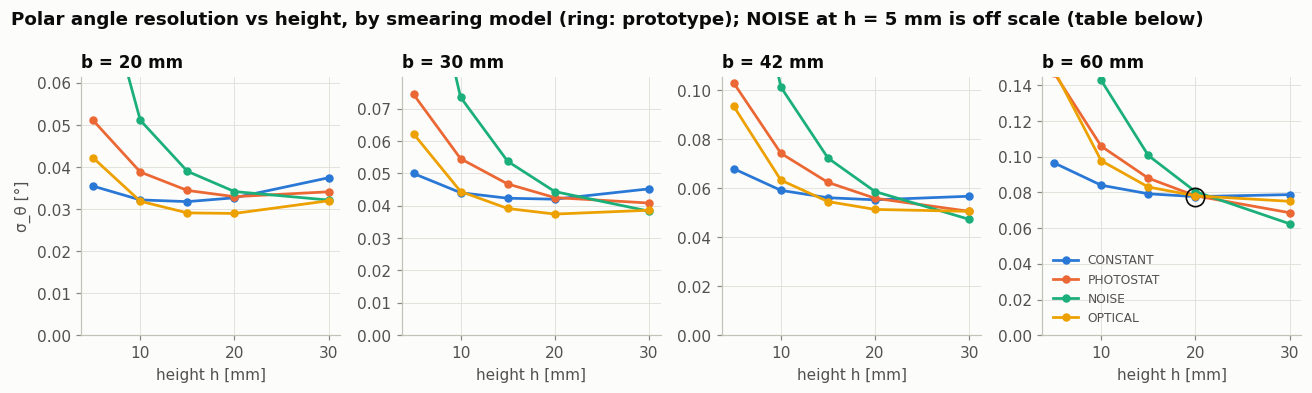

In [8]:
def by_height(col, ylabel, title):
    bases = [20, 30, 42, 60]
    fig, axs = plt.subplots(1, len(bases), figsize=(12, 3.6))
    for ax, b in zip(axs, bases):
        for i, m in enumerate(MODELS):
            g = df[(df.model == m) & (df.base_mm == b)].sort_values("height_mm")
            ax.plot(g.height_mm, g[col], "o-", color=sp.SERIES[i], ms=4.5, lw=1.8, label=m)
        top = 1.8 * df[(df.base_mm == b) & (df.height_mm == 20)][col].max()
        ax.set(title=f"b = {b} mm", xlabel="height h [mm]", ylim=(0, top))
        if b == 60:
            r = df[(df.model == "CONSTANT") & (df.base_mm == 60) & (df.height_mm == 20)].iloc[0]
            ax.plot(20, r[col], "o", ms=12, mfc="none", mec=sp.INK, mew=1.1)
    axs[0].set_ylabel(ylabel); axs[-1].legend(fontsize=8, loc="lower left")
    fig.suptitle(title + "; NOISE at h = 5 mm is off scale (table below)", x=0.01, ha="left", fontweight="bold")
    plt.tight_layout(); plt.show()

by_height("sigma_r_mm", "σ_r [mm]", "Radial position resolution vs height, by smearing model (ring: prototype)")
by_height("sigma_theta_deg", "σ_θ [°]", "Polar angle resolution vs height, by smearing model (ring: prototype)")

In [9]:
rows = []
for b, h in KEY + [(20, 5), (30, 20), (42, 20)]:
    for m in MODELS:
        r = df[(df.model == m) & (df.base_mm == b) & (df.height_mm == h)].iloc[0]
        p0 = df[(df.model == m) & (df.base_mm == 60) & (df.height_mm == 20)].iloc[0]
        rows.append({"geometry": f"{b} × {h}", "channels": int(r.channels), "model": m,
                     "σ_r [mm]": r.sigma_r_mm, "σ_rφ [mm]": r.sigma_rphi_mm, "σ_θ [°]": r.sigma_theta_deg,
                     "A of σ_φ [°]": r.sigma_phi_A_deg,
                     "gain σ_r": p0.sigma_r_mm / r.sigma_r_mm, "gain σ_θ": p0.sigma_theta_deg / r.sigma_theta_deg})
g = pd.DataFrame(rows).set_index(["geometry", "channels", "model"])
g.round({"σ_r [mm]": 3, "σ_rφ [mm]": 3, "σ_θ [°]": 4, "A of σ_φ [°]": 4, "gain σ_r": 2, "gain σ_θ": 2})

σ_r [mm]  σ_rφ [mm]  σ_θ [°]  A of σ_φ [°]  \
geometry channels model                                                   
60 × 20  28       CONSTANT      0.813      0.800   0.0777        0.0797   
                  PHOTOSTAT     0.819      0.809   0.0781        0.0805   
                  NOISE         0.847      0.845   0.0805        0.0837   
                  OPTICAL       0.819      0.809   0.0781        0.0805   
42 × 30  40       CONSTANT      0.557      0.552   0.0567        0.0584   
                  PHOTOSTAT     0.491      0.482   0.0505        0.0516   
                  NOISE         0.457      0.442   0.0472        0.0477   
                  OPTICAL       0.491      0.481   0.0505        0.0516   
30 × 30  56       CONSTANT      0.427      0.413   0.0452        0.0454   
                  PHOTOSTAT     0.380      0.362   0.0408        0.0406   
                  NOISE         0.356      0.333   0.0383        0.0377   
                  OPTICAL       0.355      0.338   0.0386        0.0384   
20 × 20  84       CONSTANT      0.296      0.285   0.0327        0.0328   
                  PHOTOSTAT     0.303      0.288   0.0329        0.0329   
                  NOISE         0.321      0.300   0.0342        0.0337   
                  OPTICAL       0.253      0.240   0.0290        0.0290   
20 × 10  84       CONSTANT      0.305      0.305   0.0322        0.0333   
                  PHOTOSTAT     0.390      0.388   0.0388        0.0401   
                  NOISE         0.539      0.534   0.0511        0.0527   
                  OPTICAL       0.304      0.301   0.0319        0.0329   
20 × 5   84       CONSTANT      0.355      0.358   0.0354        0.0372   
                  PHOTOSTAT     0.547      0.551   0.0511        0.0536   
                  NOISE         1.024      1.024   0.0921        0.0960   
                  OPTICAL       0.440      0.443   0.0421        0.0442   
30 × 20  56       CONSTANT      0.411      0.412   0.0420        0.0437   
                  PHOTOSTAT     0.418      0.416   0.0425        0.0440   
                  NOISE         0.443      0.434   0.0444        0.0454   
                  OPTICAL       0.358      0.356   0.0374        0.0387   
42 × 20  40       CONSTANT      0.563      0.564   0.0552        0.0576   
                  PHOTOSTAT     0.572      0.570   0.0558        0.0580   
                  NOISE         0.604      0.596   0.0586        0.0603   
                  OPTICAL       0.520      0.518   0.0513        0.0533   

                             gain σ_r  gain σ_θ  
geometry channels model                          
60 × 20  28       CONSTANT       1.00      1.00  
                  PHOTOSTAT      1.00      1.00  
                  NOISE          1.00      1.00  
                  OPTICAL        1.00      1.00  
42 × 30  40       CONSTANT       1.46      1.37  
                  PHOTOSTAT      1.67      1.55  
                  NOISE          1.85      1.70  
                  OPTICAL        1.67      1.55  
30 × 30  56       CONSTANT       1.90      1.72  
                  PHOTOSTAT      2.15      1.91  
                  NOISE          2.38      2.10  
                  OPTICAL        2.31      2.02  
20 × 20  84       CONSTANT       2.75      2.38  
                  PHOTOSTAT      2.70      2.37  
                  NOISE          2.64      2.36  
                  OPTICAL        3.24      2.70  
20 × 10  84       CONSTANT       2.66      2.41  
                  PHOTOSTAT      2.10      2.01  
                  NOISE          1.57      1.58  
                  OPTICAL        2.70      2.45  
20 × 5   84       CONSTANT       2.29      2.19  
                  PHOTOSTAT      1.50      1.53  
                  NOISE          0.83      0.87  
                  OPTICAL        1.86      1.85  
30 × 20  56       CONSTANT       1.98      1.85  
                  PHOTOSTAT      1.96      1.84  
                  NOISE          1.91      1.81  
                  OPTICAL   

## Conclusions

**Light collection**

* With four 6 × 6 mm² SiPMs on one end, the prototype bar (60 × 20 × 420 mm) collects ε = 12.6% of the emitted photons. A smaller cross-section is better covered by the same SiPMs: ε grows up to 28% (20 × 10 mm, ×2.2). At fixed base a taller bar collects less (larger face). At h = 5 mm the SiPMs no longer fit: the face is mostly covered, but the clipped sensors make ε drop again.
* ε falls by about 40% from the read-out end to the far end (near/far ≈ 1.4–1.6). Across the triangle it is flat within the statistical precision (≈ 1%), except for the flat 60 × 5 and 84 × 5 triangles (7–11%): the light collection does not bias η.
* The ratio ε / ε_proto used by the OPTICAL model is stable against the optical assumptions: ±2% for 30 × 30 and 42 × 30, ±8% for 20 × 20, ±10–20% for 20 × 10, i.e. at most ±4–10% on the smearing.

**Absolute scale: the test-beam smearing is not photostatistics**

* With 10 000 photons/MeV, Birks factor 0.93 and PDE 0.35, the prototype gives ≈ 410 p.e./MeV, and ≈ 120 p.e./MeV in the most pessimistic combination considered (air coupling, PDE 0.25, −30% light yield). The test-beam smearing would correspond to ≈ 24 p.e./MeV. Photostatistics therefore accounts for about 6% (at most ≈ 20%) of the variance of the test-beam smearing.
* The rest comes from sources the simulation does not describe (electronic noise, gain and calibration spread of the SiPM channels, read-out), whose energy dependence is not known. The OPTICAL model, normalised to the test beam, is thus an upper bound on the benefit of the better light collection of small bars.

**Resolution**

* At the prototype height (h = 20 mm) the energy deposits are those of the test beam, and CONSTANT, PHOTOSTAT and NOISE agree within about 8%. OPTICAL is 8–15% better for b ≤ 42 mm. The gains from a smaller base are therefore robust:

| geometry | bars | gain in position (σ_r, σ_rφ) | gain in angle (σ_θ, σ_φ) |
|---|---|---|---|
| 42 × 20 | 40 | ×1.4–1.6 | ×1.4–1.5 |
| 30 × 20 | 56 | ×1.9–2.3 | ×1.8–2.1 |
| 20 × 20 | 84 | ×2.6–3.4 | ×2.4–2.8 |

* Away from h = 20 mm the result depends on how the smearing scales with energy. Bars lower than 15 mm are good only with a gain-like (CONSTANT) smearing; they are strongly penalised if electronic noise dominates (at h = 5 mm about ×3 worse with NOISE than with CONSTANT). 30 mm tall bars are up to 15% worse or up to 28% better than 20 mm tall ones, depending on the base and on the model, and add plastic in front of the LYSO.
* **Recommendation: keep h = 20 mm and reduce the base.** 30 × 20 mm halves all four resolutions with 56 bars instead of 28, independently of the smearing model and with the same material as the prototype.
* To go further, the energy dependence of the smearing has to be measured: for example the width of the ΔE (or η) distributions as a function of the deposited energy, on a bench or in raw test-beam data, together with the pedestal noise of the SiPM channels.